# Detecting events with volatility-scaled filters

One-day price changes are converted to log returns, and recent squared deviations receive more weight in the volatility estimate:

$$
r_t^{(1d)}=\log P_t-\log P_{\ell(t)},\qquad
\widehat\sigma_t^2=\frac{\sum_{j=0}^{t}q^j\left(r_{t-j}^{(1d)}-\widehat\mu_t\right)^2}{\sum_{j=0}^{t}q^j},
\qquad q=1-\frac{2}{w+1}.
$$

Here, $P_t$ is price at time $t$; $\ell(t)$ is the latest recorded time strictly earlier than one day before $t.$ $r_t^{(1d)}$ is the one-day log return; $\widehat\mu_t$ is its weighted mean; $\widehat\sigma_t$ is estimated volatility. $q\in(0,1)$ is the decay factor; $w$ is the chosen span; $j$ counts how many observations back a return lies.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
DATA_URL = 'https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'binance'
DATA_PATH = ensure_dataset(ROOT, 'binance_btcusdt')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
public_columns = ['Open time', 'Open', 'High', 'Low', 'Close', 'Volume', 'Close time', 'Quote volume', 'Trades', 'Buyer base volume', 'Buyer quote volume', 'Unused']
raw = pd.read_csv(DATA_PATH, compression='zip', header=None, names=public_columns, nrows=None)
raw['time'] = pd.to_datetime(raw['Open time'], unit='ms', utc=True).dt.tz_convert(None)
raw = raw.rename(columns={'Close': 'close', 'Volume': 'volume', 'Quote volume': 'quote_volume', 'Trades': 'trades'})
raw = raw.sort_values('time').drop_duplicates('time').reset_index(drop=True)
from RiskLabAI.data.labeling import cusum_filter_events_dynamic_threshold, daily_volatility_with_log_returns, symmetric_cusum_filter
FIGURES = ROOT / 'outputs' / 'figures' / '06_financial_labels'
TABLES = ROOT / 'outputs' / 'tables' / '06_financial_labels'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')
raw = raw.sort_values('time').dropna(subset=['time', 'close']).drop_duplicates('time').reset_index(drop=True)
close = pd.Series(raw['close'].to_numpy(dtype=float), index=pd.DatetimeIndex(raw['time']), name='Price')
log_price = np.log(close)
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Scaling one-day changes by volatility

,Field,Value
0,Archive,BTCUSDT-1m-2021-1zip
1,Provider,Binance Data Vision
2,Public access,Direct public download
3,Market,Bitcoin quoted in USDT
4,Sample start,2021-01-01 00:00:00
5,Sample end,2021-01-31 23:59:00
6,Records,"44,640"
7,Interval,One minute


,Quantity,Summary,Value
0,One-day log return,Standard deviation,0.065720
1,Estimated volatility,10th percentile,0.006004
2,Estimated volatility,Middle value,0.010700
3,Estimated volatility,90th percentile,0.019746


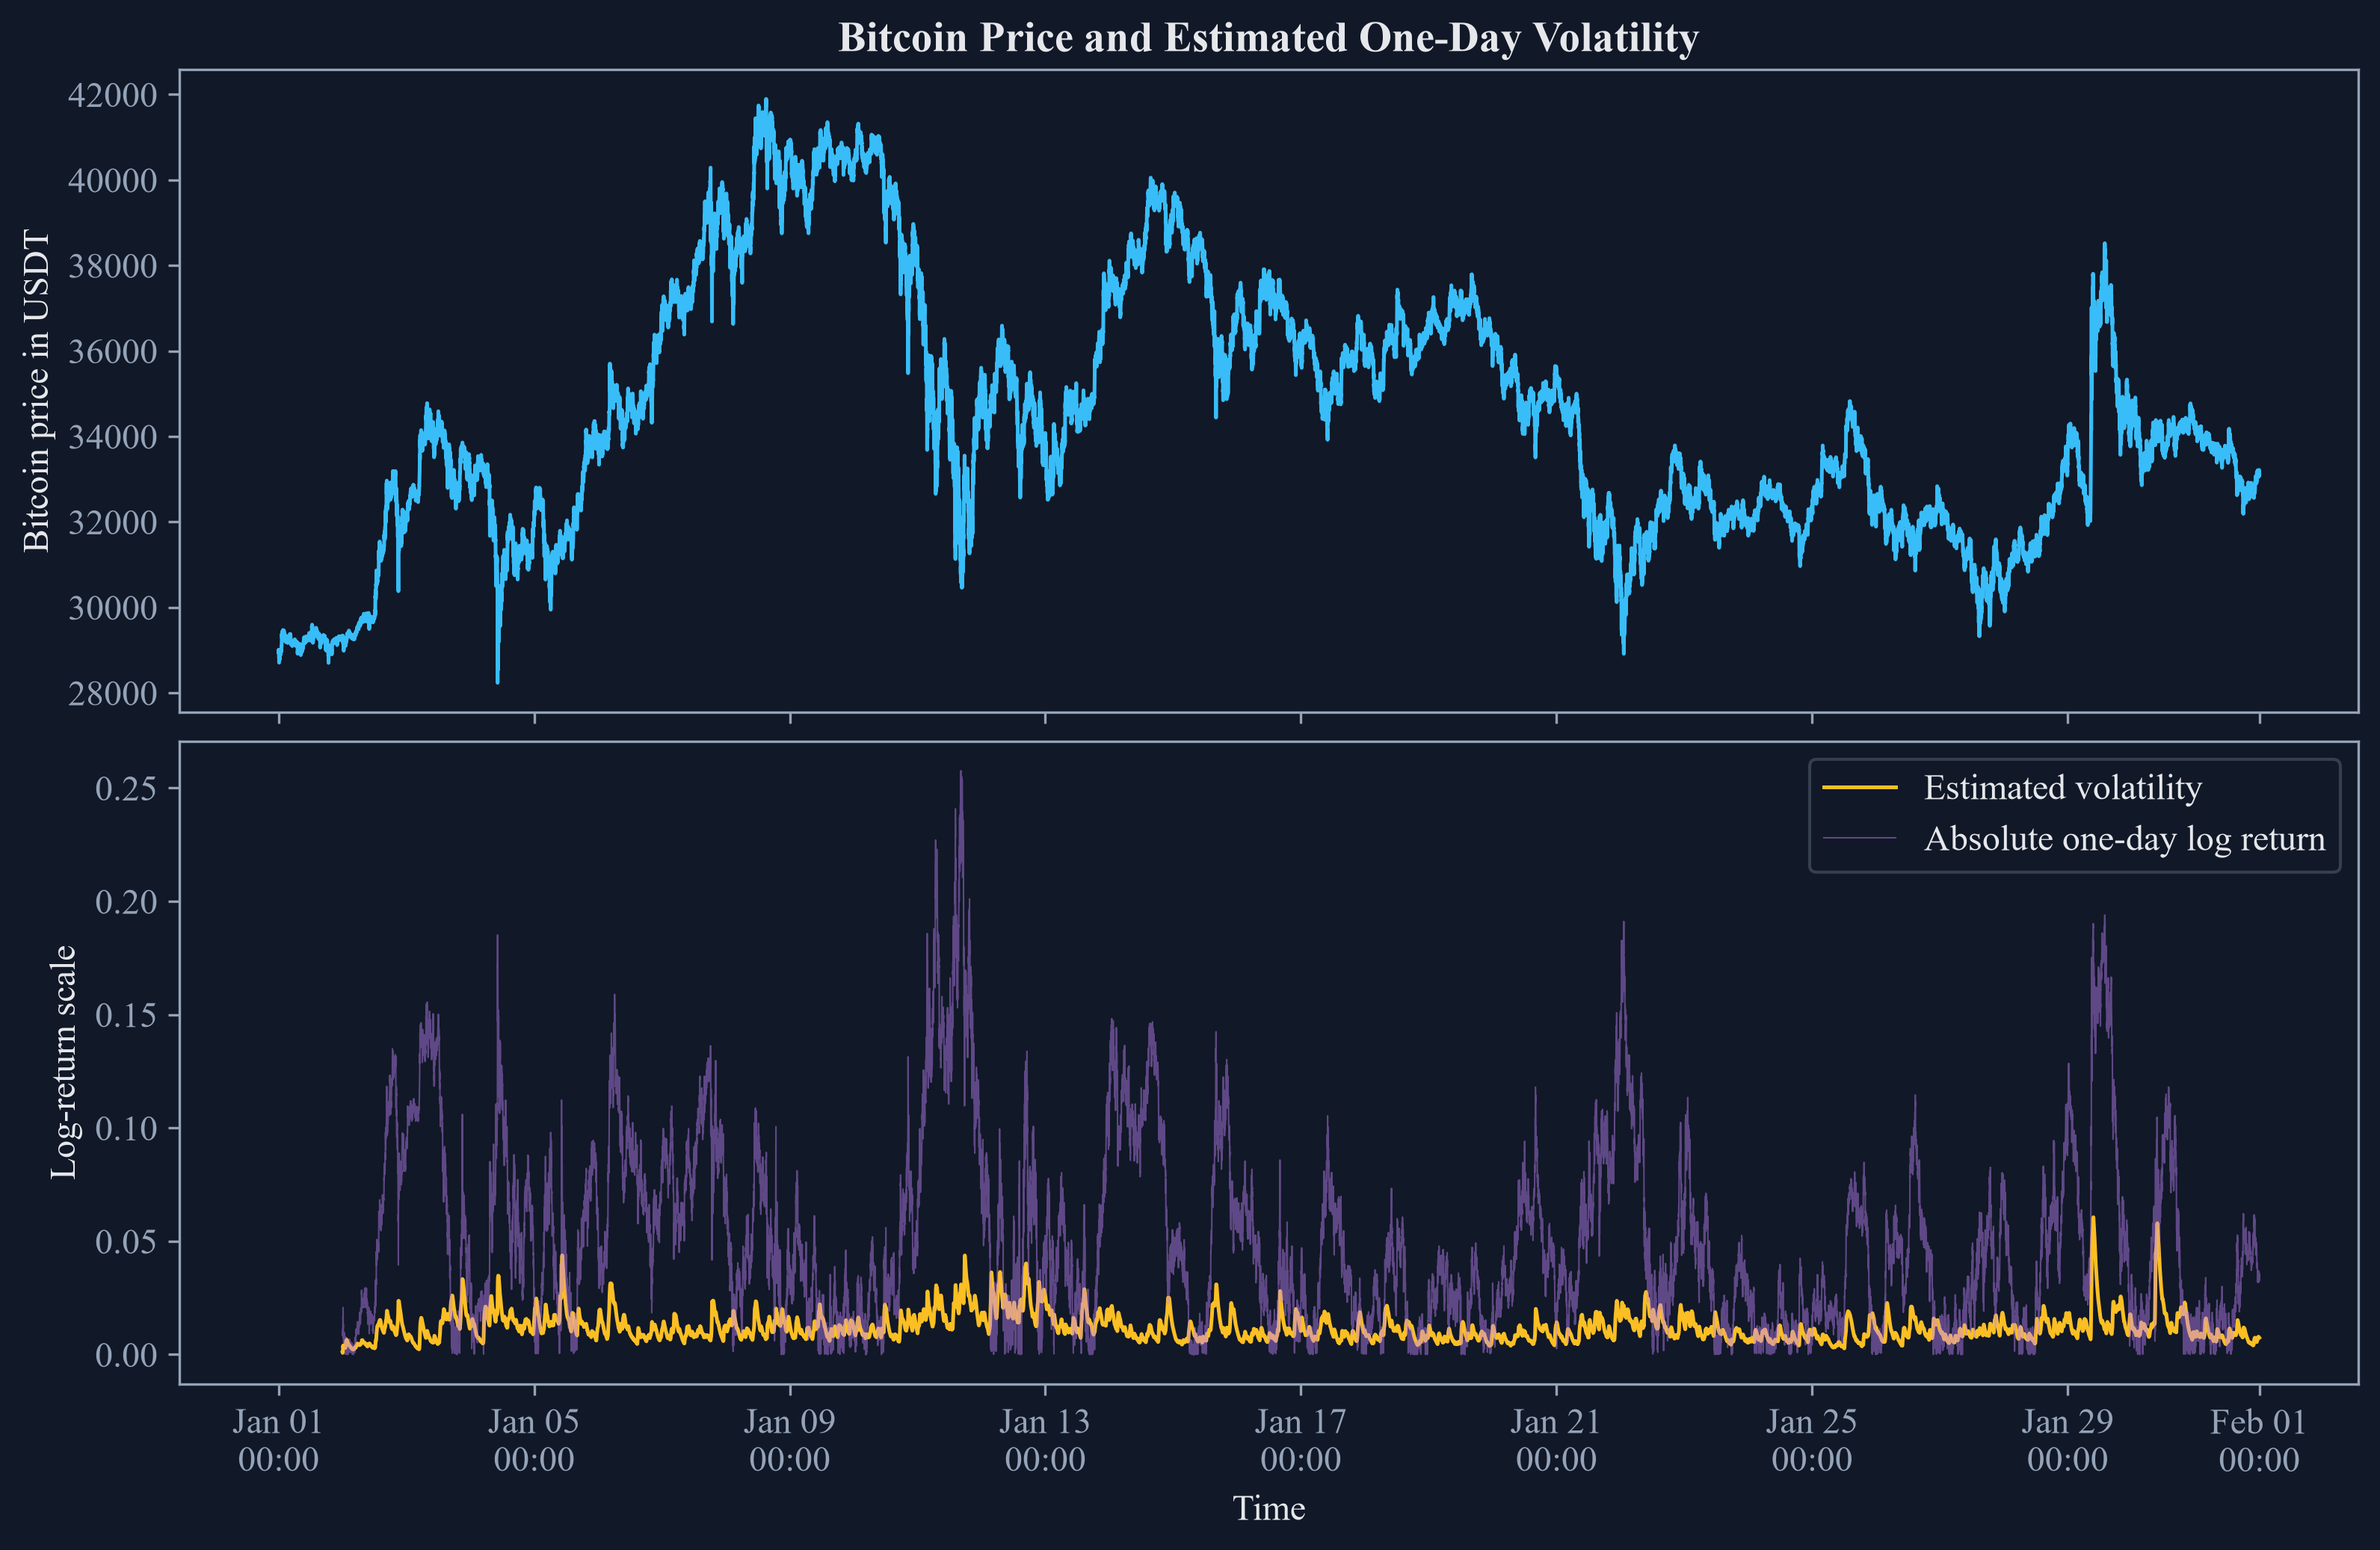

In [2]:
span = 100
volatility = daily_volatility_with_log_returns(close, span=span)
lag_positions = close.index.searchsorted(close.index - pd.Timedelta(days=1))
lag_positions = lag_positions[lag_positions > 0]
lag_times = pd.Series(close.index[lag_positions - 1], index=close.index[close.shape[0] - lag_positions.shape[0]:])
one_day_return = np.log(close.loc[lag_times.index] / close.loc[lag_times.values].to_numpy())
independent_volatility = one_day_return.ewm(span=span).std().rename('Independent volatility')
data_provenance = pd.DataFrame({'Field': ['Archive', 'Provider', 'Public access', 'Market', 'Sample start', 'Sample end', 'Records', 'Interval'], 'Value': ['BTCUSDT-1m-2021-01.zip', 'Binance Data Vision', 'Direct public download', 'Bitcoin quoted in USDT', str(close.index.min()), str(close.index.max()), f'{len(close):,}', 'One minute']})
volatility_summary = pd.DataFrame({'Quantity': ['One-day log return', 'Estimated volatility', 'Estimated volatility', 'Estimated volatility'], 'Summary': ['Standard deviation', '10th percentile', 'Middle value', '90th percentile'], 'Value': [one_day_return.std(), volatility.quantile(0.1), volatility.median(), volatility.quantile(0.9)]})
save_table(data_provenance, 'data_provenance', 'Public data used for the Chapter 5 experiments.', 'tab:chapter5-data-provenance', fit=True)
save_table(volatility_summary, 'volatility_summary', 'One-day return and volatility summaries for the 31-day sample.', 'tab:volatility-summary', float_format='%.6f', fit=False)
display(data_provenance)
display(volatility_summary.round(6))
figure, axes = plt.subplots(2, 1, figsize=(10.5, 6.8), sharex=True, constrained_layout=True)
axes[0].plot(close.index, close, color=palette['cyan'], linewidth=1.2)
axes[0].set_ylabel('Bitcoin price in USDT')
axes[0].set_title('Bitcoin Price and Estimated One-Day Volatility')
axes[1].plot(volatility.index, volatility, color=palette['amber'], linewidth=1.2, label='Estimated volatility')
axes[1].plot(one_day_return.index, one_day_return.abs(), color=palette['violet'], linewidth=0.5, alpha=0.45, label='Absolute one-day log return')
axes[1].set_ylabel('Log-return scale')
axes[1].set_xlabel('Time')
axes[1].legend()
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %d\n%H:%M'))
figure.savefig(FIGURES / 'price_and_volatility.png', bbox_inches='tight', dpi=300)
figure.savefig(FIGURES / 'price_and_volatility.pdf', bbox_inches='tight')
display(Image(filename=str(FIGURES / 'price_and_volatility.png')))
plt.close(figure)


## Symmetric Cumulative Filter

Positive and negative movements accumulate separately, while movement in the opposite direction pulls each total back toward zero:

$$
S_t^+=\max\{0,S_{t-1}^++\Delta x_t\},\qquad
S_t^-=\min\{0,S_{t-1}^-+\Delta x_t\},\qquad
\Delta x_t=x_t-x_{t-1}.
$$

Here, $x_t$ is the measured series at time $t$; $\Delta x_t$ is its one-step change. $S_t^+\geq0$ is the positive cumulative total; $S_t^-\leq0$ is the negative cumulative total; both start at zero.

In [3]:
fixed_threshold = 0.02
dynamic_multiplier = 2.0
fixed_events = symmetric_cusum_filter(log_price, fixed_threshold)
dynamic_threshold = (dynamic_multiplier * volatility).dropna()
dynamic_events = cusum_filter_events_dynamic_threshold(log_price, dynamic_threshold)

sensitivity_records = []
for level in [0.01, 0.02, 0.03]:
    selected = symmetric_cusum_filter(log_price, level)
    gaps = pd.Series(selected).diff().dt.total_seconds().div(60.0).dropna()
    sensitivity_records.append({"Threshold rule": "Fixed log-price change", "Threshold level": level, "Events": len(selected), "Middle gap in minutes": gaps.median()})
for multiplier in [1.0, 1.5, 2.0]:
    selected = cusum_filter_events_dynamic_threshold(log_price, (multiplier * volatility).dropna())
    gaps = pd.Series(selected).diff().dt.total_seconds().div(60.0).dropna()
    sensitivity_records.append({"Threshold rule": "Multiple of estimated volatility", "Threshold level": multiplier, "Events": len(selected), "Middle gap in minutes": gaps.median()})
threshold_sensitivity = pd.DataFrame(sensitivity_records)
sample_days = raw["time"].dt.normalize().nunique()
event_summary = pd.DataFrame({
    "Rule": ["Fixed threshold", "Changing threshold"],
    "Chosen level": [f"{fixed_threshold:.3f} log-price units", f"{dynamic_multiplier:.1f} times estimated volatility"],
    "Events": [len(fixed_events), len(dynamic_events)],
    "Events per day": [len(fixed_events) / sample_days, len(dynamic_events) / sample_days],
})
save_table(event_summary, "event_filter_summary", "Event counts under fixed and changing cumulative thresholds.", "tab:event-filter-summary", float_format="%.3f", fit=False)
save_table(threshold_sensitivity, "event_threshold_sensitivity", "Event counts and waiting times across threshold choices.", "tab:event-threshold-sensitivity", float_format="%.3f", fit=True)
display(event_summary.round(3))
display(threshold_sensitivity.round(3))

,Rule,Chosen level,Events,Events per day
0,Fixed threshold,0.020 log-price units,643,20.742
1,Changing threshold,2 times estimated volatility,540,17.419


,Threshold rule,Threshold level,Events,Middle gap in minutes
0,Fixed log-price change,0.01,2005,15
1,Fixed log-price change,0.02,643,45
2,Fixed log-price change,0.03,322,103
3,Multiple of estimated volatility,1,1705,18
4,Multiple of estimated volatility,1.50,869,37
5,Multiple of estimated volatility,2,540,64


## First Crossings

Event $k$ occurs at the first time either cumulative total passes its current threshold:

$$
\tau_k=\inf\{t>\tau_{k-1}:S_t^+>h_t\ \text{or}\ S_t^-<-h_t\}.
$$

Here, $\tau_k$ is the time of event $k$; $\tau_{k-1}$ is the preceding event time; $t$ is a candidate time. $S_t^+$ and $S_t^-$ are the positive and negative totals; $h_t>0$ is the fixed or changing threshold; $\inf$ selects the first crossing.

,Direction,Crossings,Smallest excess
0,Positive,320,9.200000e-07
1,Negative,323,1.320000e-05
2,All,643,9.200000e-07


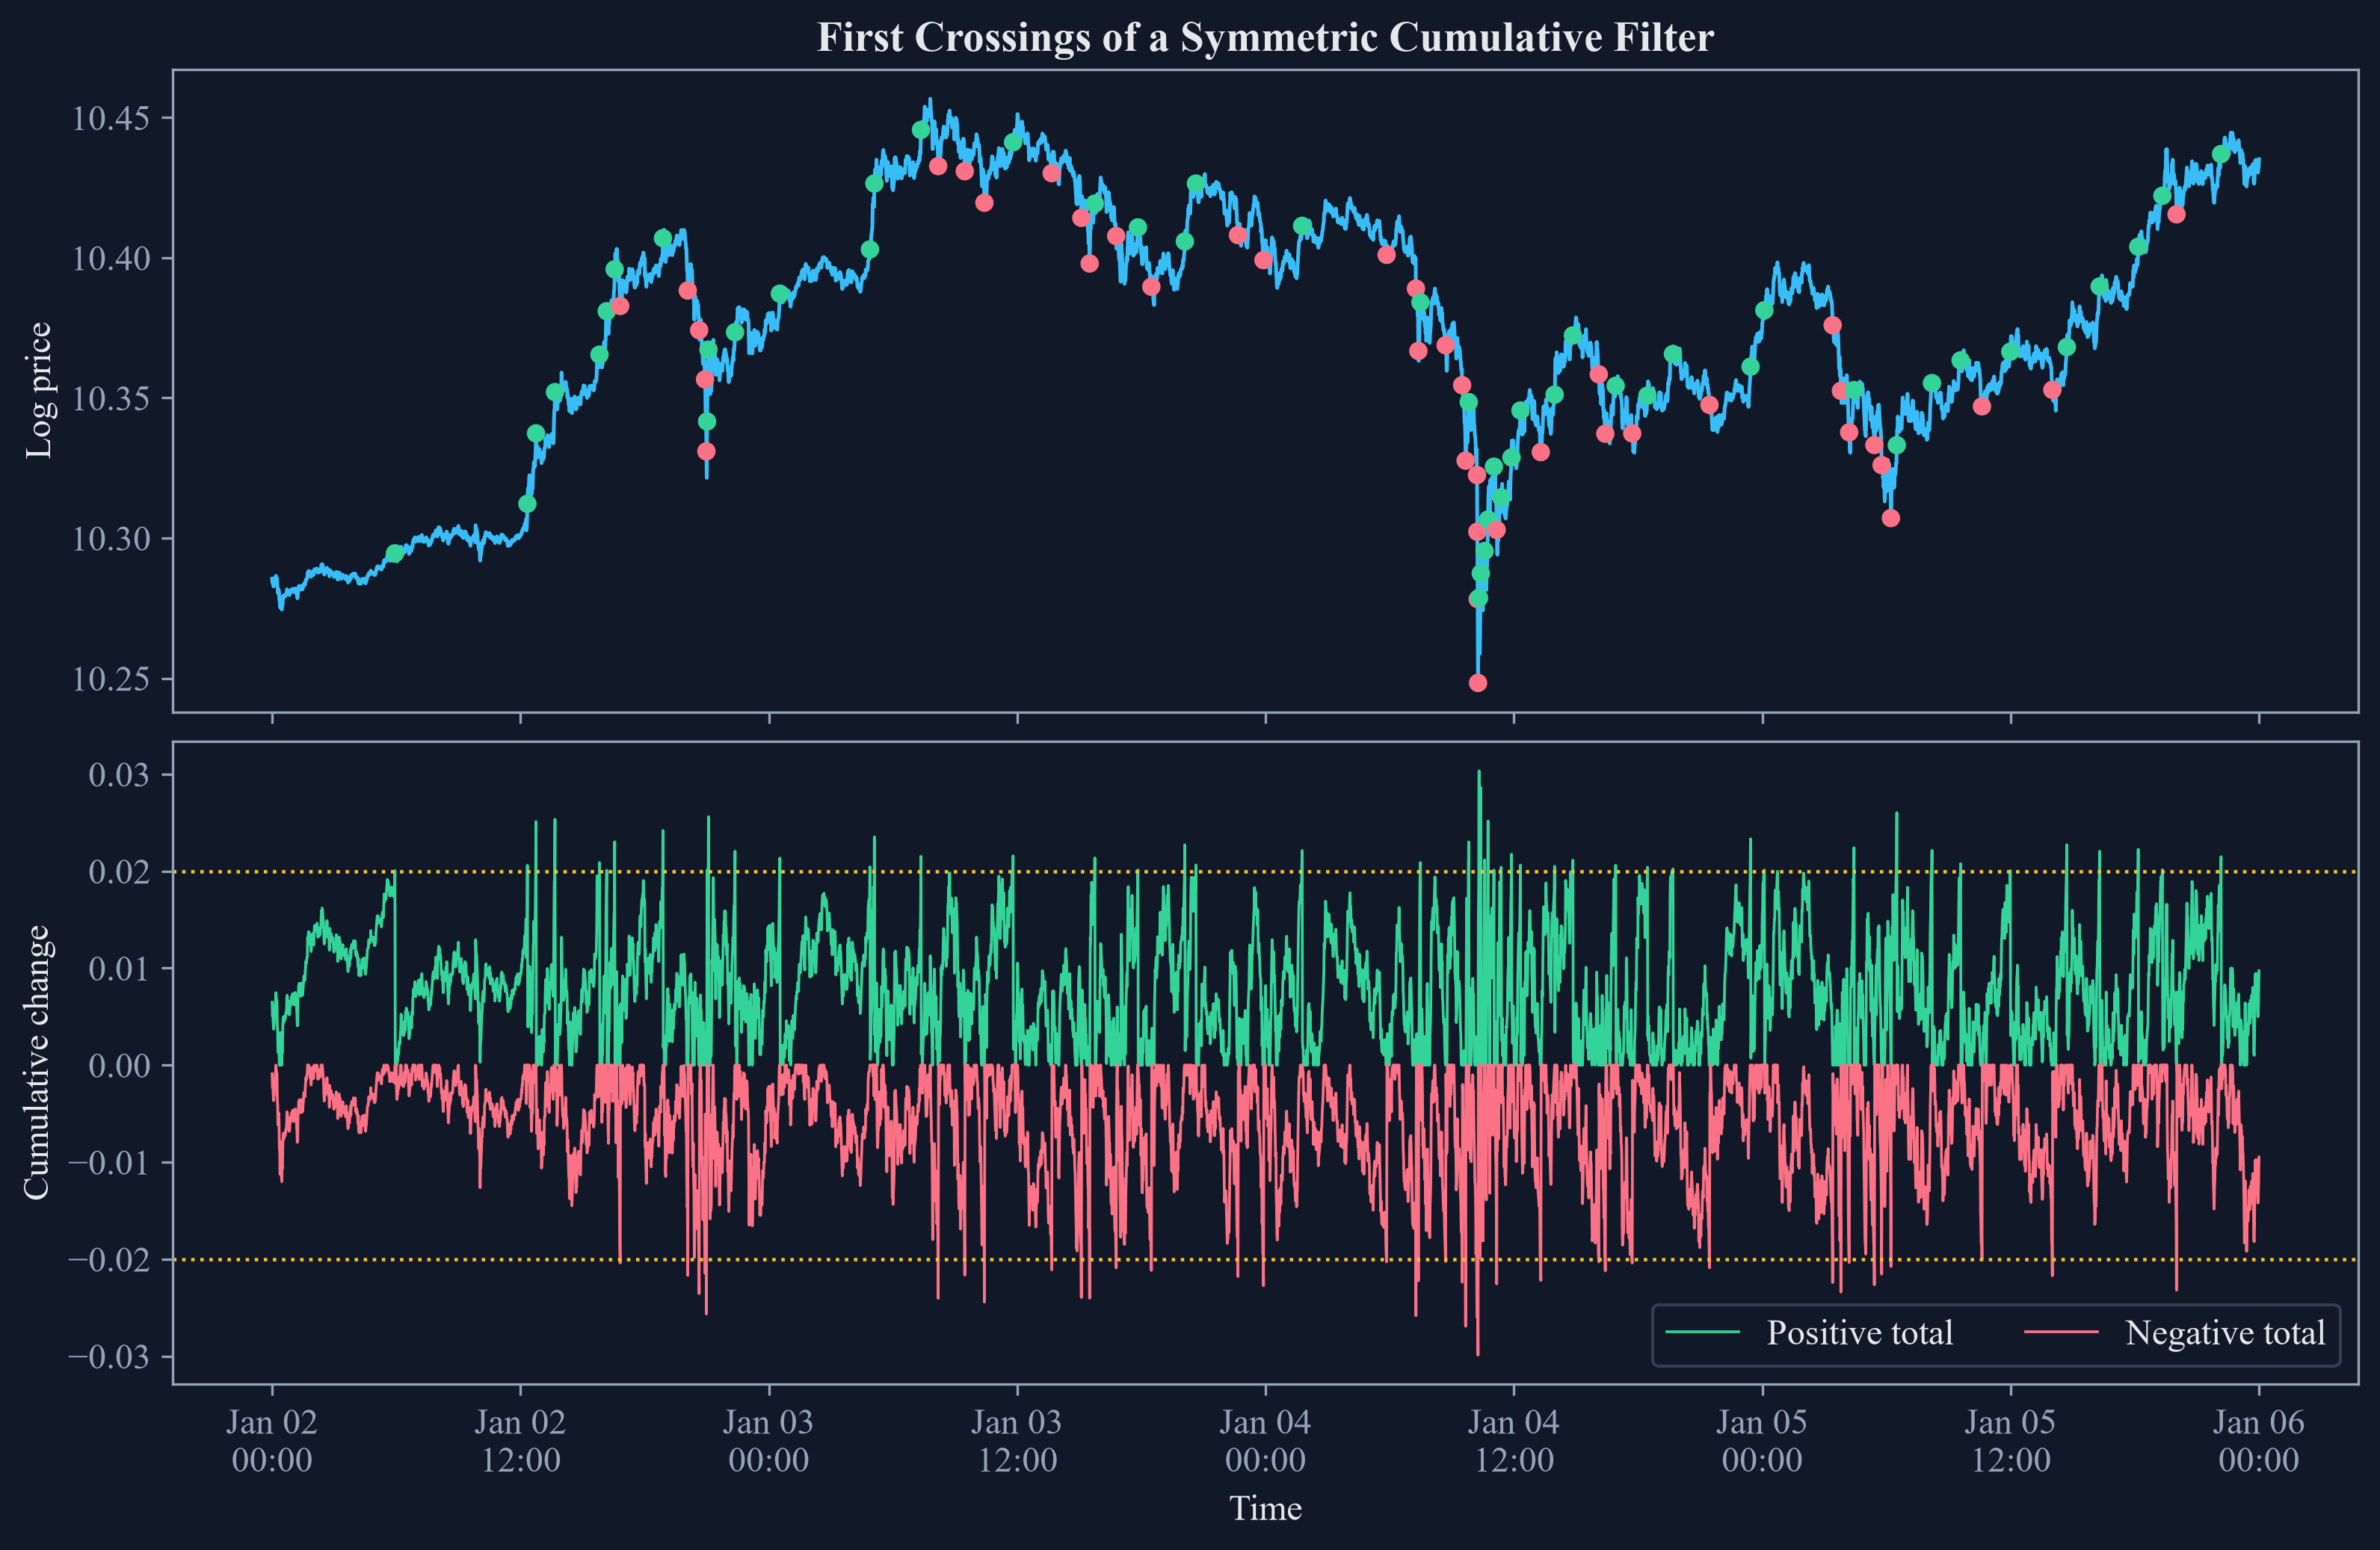

In [4]:
def cumulative_trace(series, threshold):
    changes = series.diff().dropna()
    positive = 0.0
    negative = 0.0
    rows = []
    for time, change in changes.items():
        positive_before_reset = max(0.0, positive + change)
        negative_before_reset = min(0.0, negative + change)
        direction = 0
        positive = positive_before_reset
        negative = negative_before_reset
        if negative_before_reset < -threshold:
            direction = -1
            negative = 0.0
        elif positive_before_reset > threshold:
            direction = 1
            positive = 0.0
        rows.append((time, change, positive_before_reset, negative_before_reset, positive, negative, direction))
    return pd.DataFrame(rows, columns=["Time", "Change", "Positive before reset", "Negative before reset", "Positive after reset", "Negative after reset", "Direction"]).set_index("Time")

trace = cumulative_trace(log_price, fixed_threshold)
crossings = trace.loc[trace["Direction"] != 0].copy()
positive_excess = crossings.loc[crossings["Direction"] == 1, "Positive before reset"] - fixed_threshold
negative_excess = -crossings.loc[crossings["Direction"] == -1, "Negative before reset"] - fixed_threshold
first_crossing_check = pd.DataFrame({
    "Direction": ["Positive", "Negative", "All"],
    "Crossings": [(crossings["Direction"] == 1).sum(), (crossings["Direction"] == -1).sum(), len(crossings)],
    "Smallest excess": [positive_excess.min(), negative_excess.min(), pd.concat([positive_excess, negative_excess]).min()],
})
save_table(first_crossing_check, "cusum_first_crossing_check", "Checks of strict first crossings under the fixed cumulative threshold.", "tab:cusum-first-crossing", float_format="%.8f", fit=False)
display(first_crossing_check.round(8))

view_start = close.index[1440]
view_end = close.index[7200]
view = trace.loc[view_start:view_end]
view_events = crossings.loc[view_start:view_end]
figure, axes = plt.subplots(2, 1, figsize=(10.5, 6.8), sharex=True, constrained_layout=True)
axes[0].plot(log_price.loc[view_start:view_end].index, log_price.loc[view_start:view_end], color=palette["cyan"], linewidth=1.2)
axes[0].scatter(view_events.index, log_price.reindex(view_events.index), c=np.where(view_events["Direction"] > 0, palette["green"], palette["rose"]), s=24, zorder=4)
axes[0].set_ylabel("Log price")
axes[0].set_title("First Crossings of a Symmetric Cumulative Filter")
axes[1].plot(view.index, view["Positive before reset"], color=palette["green"], linewidth=0.9, label="Positive total")
axes[1].plot(view.index, view["Negative before reset"], color=palette["rose"], linewidth=0.9, label="Negative total")
axes[1].axhline(fixed_threshold, color=palette["amber"], linewidth=1.1, linestyle=":")
axes[1].axhline(-fixed_threshold, color=palette["amber"], linewidth=1.1, linestyle=":")
axes[1].set_ylabel("Cumulative change")
axes[1].set_xlabel("Time")
axes[1].legend(ncol=2)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%H:%M"))
figure.savefig(FIGURES / "cusum_first_crossings.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "cusum_first_crossings.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "cusum_first_crossings.png")))
plt.close(figure)

## Changing-Threshold Event Map

,Quantity,Value
0,Events,540
1,Positive event changes,274
2,Negative event changes,266
3,Middle absolute event change,0.002795
4,90th percentile absolute event change,0.006583


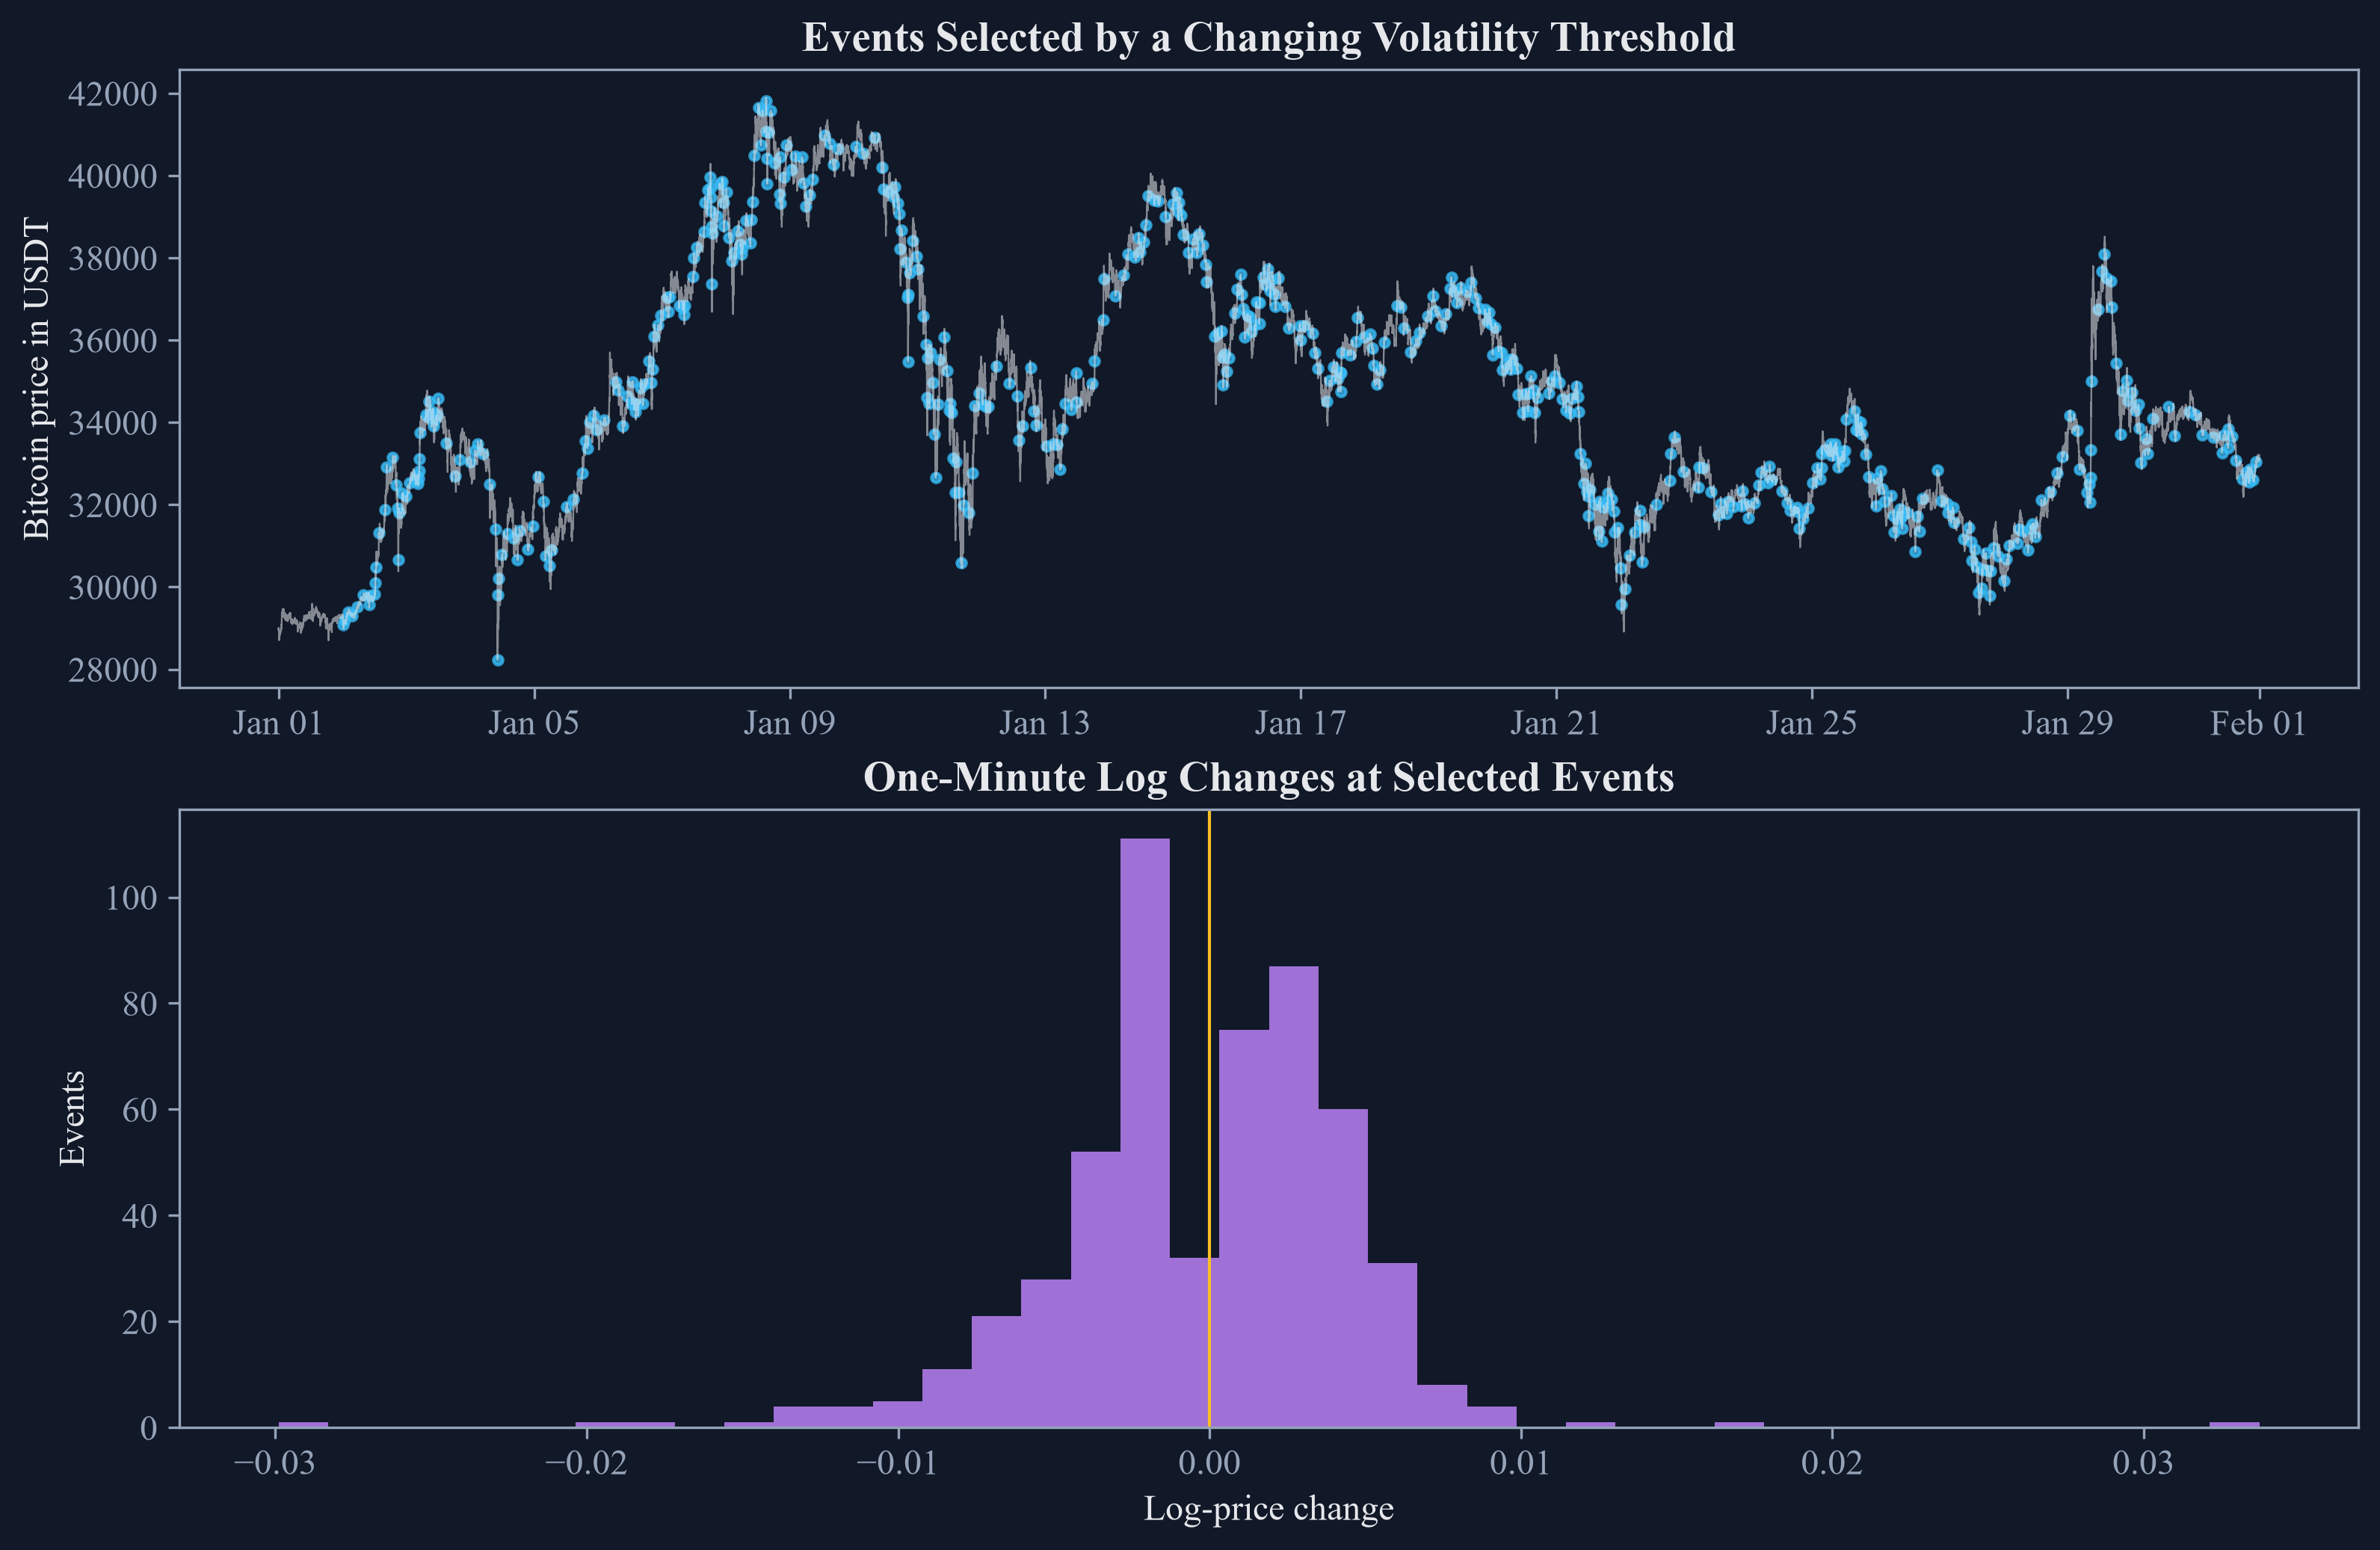

In [5]:
dynamic_event_changes = log_price.diff().reindex(dynamic_events).dropna()
dynamic_event_summary = pd.DataFrame({
    "Quantity": ["Events", "Positive event changes", "Negative event changes", "Middle absolute event change", "90th percentile absolute event change"],
    "Value": [len(dynamic_events), int((dynamic_event_changes > 0).sum()), int((dynamic_event_changes < 0).sum()), dynamic_event_changes.abs().median(), dynamic_event_changes.abs().quantile(0.90)],
})
save_table(dynamic_event_summary, "dynamic_event_summary", "Events selected by the changing volatility threshold.", "tab:chapter5-dynamic-events", fit=True)
display(dynamic_event_summary.round(6))

figure, axes = plt.subplots(2, 1, figsize=(10.5, 6.8), constrained_layout=True)
axes[0].plot(close.index, close, color=palette["text"], linewidth=0.55, alpha=0.55)
axes[0].scatter(dynamic_events, close.reindex(dynamic_events), color=palette["cyan"], s=9, alpha=0.75)
axes[0].set_title("Events Selected by a Changing Volatility Threshold")
axes[0].set_ylabel("Bitcoin price in USDT")
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
axes[1].hist(dynamic_event_changes, bins=40, color=palette["violet"], alpha=0.82)
axes[1].axvline(0.0, color=palette["amber"], linewidth=1.0)
axes[1].set_title("One-Minute Log Changes at Selected Events")
axes[1].set_xlabel("Log-price change")
axes[1].set_ylabel("Events")
figure.savefig(FIGURES / "dynamic_cusum_events.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "dynamic_cusum_events.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "dynamic_cusum_events.png")))
plt.close(figure)

## Tests

In [6]:
controlled_dates = pd.date_range('2020-01-01', periods=20, freq='D')
controlled_prices = pd.Series([10, 11, 12, 13, 14, 15, 14, 13, 12, 11, 10, 11, 12, 11, 12, 11, 12, 13, 14, 15], index=controlled_dates, dtype=float)
controlled_events = symmetric_cusum_filter(controlled_prices, 3.0)
expected_events = pd.to_datetime(['2020-01-05', '2020-01-10', '2020-01-19'])
pd.testing.assert_index_equal(controlled_events, expected_events)
pd.testing.assert_series_equal(volatility, independent_volatility.rename('std'))
pd.testing.assert_index_equal(fixed_events, crossings.index, check_names=False)
assert len(close) == 44640
assert close.index.is_monotonic_increasing
assert close.index.is_unique
assert np.all(close > 0.0)
assert volatility.dropna().gt(0.0).all()
assert len(fixed_events) > 0
assert len(dynamic_events) > 0
assert sample_days == 31
assert np.all(positive_excess > 0.0)
assert np.all(negative_excess > 0.0)
assert threshold_sensitivity.loc[threshold_sensitivity['Threshold rule'] == 'Fixed log-price change', 'Events'].is_monotonic_decreasing
assert threshold_sensitivity.loc[threshold_sensitivity['Threshold rule'] == 'Multiple of estimated volatility', 'Events'].is_monotonic_decreasing
assert dynamic_event_summary.loc[dynamic_event_summary['Quantity'] == 'Events', 'Value'].iloc[0] == len(dynamic_events)
assert len(dynamic_event_changes) == len(dynamic_events)
assert (FIGURES / 'dynamic_cusum_events.pdf').is_file()
assert (TABLES / 'dynamic_event_summary.tex').is_file()
